# Q2. How many numbers are smaller than the current number
Given the array nums, for each nums[i] find out how many numbers in the array are smaller than it. That is, for each nums[i] you have to count the number of valid j's such that j != i and nums[j] < nums[i].

Return the answer in an array.

Example 1:

Input: nums = [8,1,2,2,3]
Output: [4,0,1,1,3]
Explanation:
For nums[0]=8 there exist four smaller numbers than it (1, 2, 2 and 3).
For nums[1]=1 does not exist any smaller number than it.
For nums[2]=2 there exist one smaller number than it (1).
For nums[3]=2 there exist one smaller number than it (1).
For nums[4]=3 there exist three smaller numbers than it (1, 2 and 2).
Example 2:

Input: nums = [6,5,4,8]
Output: [2,1,0,3]
Example 3:

Input: nums = [7,7,7,7]
Output: [0,0,0,0]

Есть две идеи для решения данной задачи: 1-ое - максимально простое - заключается в проходе по вложенному массиву (сложность O(n^2)). 2-ое чуть более сложное и, вероятно, не принесёт должного ускорения, заключается в создании set, его сортировки и создания на его основе map, чтобы в конце пройтись по массиву 1 раз. Теоретическая сложность O(nlog(n)+n+n) при quicksort. Ради прикола второй я тоже реализую, но не думаю, что оно будет эффективным.

# Простой способ (в лоб)

In [5]:
class Solution {
    fun smallerNumbersThanCurrent(nums: IntArray): IntArray {
        val n = nums.size
        val counter = IntArray(n)

        for (i in 0..<n)
        {
            for (j in 0..<n)
            {
                if(nums[j] < nums[i])
                    counter[i]+=1
            }
        }

        return counter
    }
}

In [9]:
fun printIntArray (nums: IntArray) {
    for (i in nums)
        print("$i ")
    println()
}


val solution = Solution()

val example1 = solution.smallerNumbersThanCurrent(intArrayOf(8,1,2,2,3))

printIntArray(example1)

val example2 = solution.smallerNumbersThanCurrent(intArrayOf(6,5,4,8))

printIntArray(example2)

4 0 1 1 3 
2 1 0 3 


# Результат
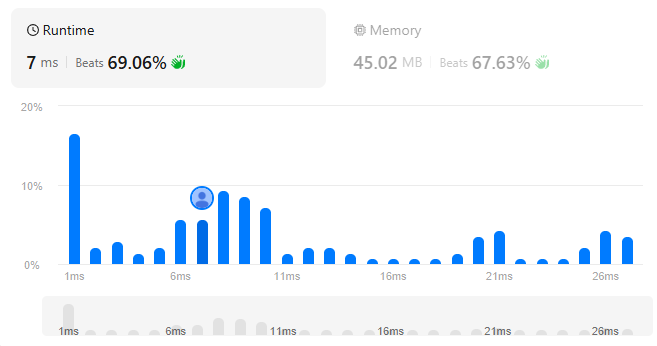

# 2-ой способ

In [10]:
class Solution {
    fun smallerNumbersThanCurrent(nums: IntArray): IntArray {
        val n = nums.size
        val numsSet = nums.toSortedSet().toIntArray()
        val mp = mutableMapOf<Int, Int>()

        for (i in 0..<numsSet.size)
        {
            mp.put( numsSet[i], i)
        }

        val counter = IntArray(n)

        for (i in 0..<n)
        {
            counter[i] = mp[ nums[i] ]!!
        }

        return counter
    }
}

In [11]:
fun printIntArray (nums: IntArray) {
    for (i in nums)
        print("$i ")
    println()
}


val solution = Solution()

val example1 = solution.smallerNumbersThanCurrent(intArrayOf(8,1,2,2,3))

printIntArray(example1)

val example2 = solution.smallerNumbersThanCurrent(intArrayOf(6,5,4,8))

printIntArray(example2)

3 0 1 1 2 
2 1 0 3 


Плохая идея. Не буду дальше реализовывать.
Самое эффективное решение гениально. Оно заключается сначала в подсчёте частоты встречи числа в массиве, а потом создании массива с префиксными суммами (a[i] += a[i-1)